<a href="https://colab.research.google.com/github/dtorresmarin-cell/apuntes-r-ml/blob/main/Ruta%3A%2004-modelos/Regresi%C3%B3n_Lineal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Regresión Lineal**

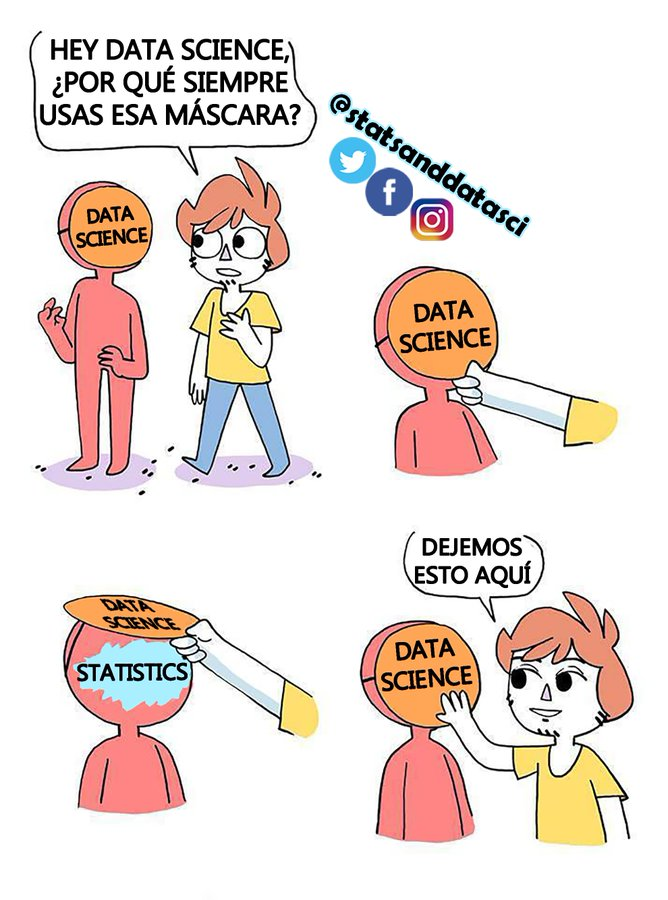

**Definición:** consiste en generar un modelo de regresión (ecuación de la recta), que permita explicar la relación lineal que existe entre dos o más variables. A la variable dependiente se la identifica como Y a las predictoras o independientes como X.

$$Y=\beta_0 + \beta_1 X_1 + ϵ$$

La regresión es una familia de técnicas para modelar y analizar la relación entre una target y uno o más features. Su propósito principal es entender cómo cambia el valor de Y cuando cambia el valor de X.

Siendo $β_0$ la ordenada de la origen, es decir, cuando vale Y cuando X es 0. Mientras que $β_1$ es la pendiente, es decir, cuando sube Y por unidad de X que aumenta. Por último, $ϵ$ es el error aleatorio que absorbe el efecto de las variables omitidas. Los coeficientes $β_0$ y $β_1$ son desconocidos y se calculan en base a aquellos valores que dan el mínimo de suma de errores al cuadrado.

**Método de Mínimos Cuadrados**:  Es el método matemático que busca la "mejor" recta ajustando los coeficientes ($\beta_0$ y $\beta_1$) para que la suma de los errores elevados al cuadrado sea la menor posible (mínima).

Cuando la computadora calcula la recta "perfecta" (por el método de Mínimos Cuadrados Ordinarios), lo que hace es tomar los errores de todos los puntos de tus datos, elevarlos al cuadrado para que los positivos y negativos no se cancelen, y buscar la línea que haga esa suma de errores lo más pequeña posible: $$SSR= \sum_{i=1}^{n} (y_i - \hat{y_i})^2$$

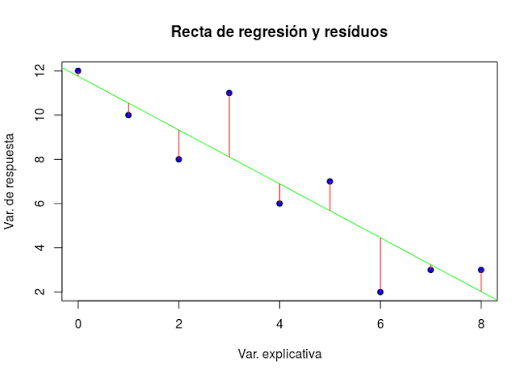

**El proceso:**

**Etapa 1:** Entrenamiento (Ajuste del Modelo)

Le entregas al algoritmo tu dataset con filas/registros reales:

- Feature / Variable independiente ($X$): Metros cuadrados.

- Target / Variable dependiente ($Y$): Precio real del departamento.

El algoritmo OLS (Mínimos Cuadrados Ordinarios) "prueba" infinitas rectas probables y calcula la Suma de Errores al Cuadrado (SSR) para cada una.Encuentra matemáticamente los coeficientes óptimos ($\hat{\beta}_0$ y $\hat{\beta}_1$) que minimizan esa suma de errores.

Resultado de esta etapa: Obtienes la ecuación final de la recta ajustada:

$$\hat{Y} = \hat{\beta}_0 + \hat{\beta}_1 X$$

**Etapa 2: Predicción (Inferencia)**

Una vez guardados los coeficientes ($\hat{\beta}_0$ y $\hat{\beta}_1$), la etapa de aprendizaje terminó.Cuando llega un nuevo departamento al que solo le conoces la feature ($X = 75\text{ m}^2$):Le pasas únicamente esa $X$ al modelo. El modelo sustituye $X$ en la recta y te devuelve el valor predicho ($\hat{Y}$):


$$\hat{\text{Precio}} = \hat{\beta}_0 + \hat{\beta}_1 (75)$$

*Ejemplo con IRIS*

In [8]:
data(iris) #cargamos la bd
modelo_lm <- lm(Sepal.Width ~ Sepal.Length, data = iris) # a la izq va el target separado por ~
summary(modelo_lm)


Call:
lm(formula = Sepal.Width ~ Sepal.Length, data = iris)

Residuals:
    Min      1Q  Median      3Q     Max 
-1.1095 -0.2454 -0.0167  0.2763  1.3338 

Coefficients:
             Estimate Std. Error t value Pr(>|t|)    
(Intercept)   3.41895    0.25356   13.48   <2e-16 ***
Sepal.Length -0.06188    0.04297   -1.44    0.152    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.4343 on 148 degrees of freedom
Multiple R-squared:  0.01382,	Adjusted R-squared:  0.007159 
F-statistic: 2.074 on 1 and 148 DF,  p-value: 0.1519


1. El Intercepto: es el valor esperado de la variable dependiente (Sepal.Width) cuando la variable independiente (Sepal.Length) vale exactamente 0.Si una flor tuviera un largo de sépalo de 0cm, su ancho de sépalo estimado sería de 3.42cm (en este contexto es un valor teórico/matemático para posicionar la recta).

2. La Pendiente: muestra cuánto cambia en promedio la variable dependiente (Sepal.Width) por cada unidad que aumenta la variable independiente (Sepal.Length).Por cada centímetro adicional de largo de sépalo, el ancho del sépalo disminuye en promedio 0.062cm (cambio negativo).

**Supuestos de Regresión Lineal**
- Independencia
- Linealidad
- Homocedasticidad
- Normalidad
- No autocorrelación

**Linealidad**: verifica que la relación entre  Y e X sea verdaderamente una línea recta.

El método es un grádico de residuales vs. valores ajustados, la línea roja es la tendencia media de los residuos, lo idea es que sea completamente horizontal O.
Cada punto representa el error de predicción para una observación, lo ideal es que se distribuyan sin ningún patrón claro. Fitted values son los valores predichos y Residuals son los errores o residuos.
Mientras más cerca a 0, o a la recta, significa que las predicciones son exactas y logró capturar una relación el modelo.

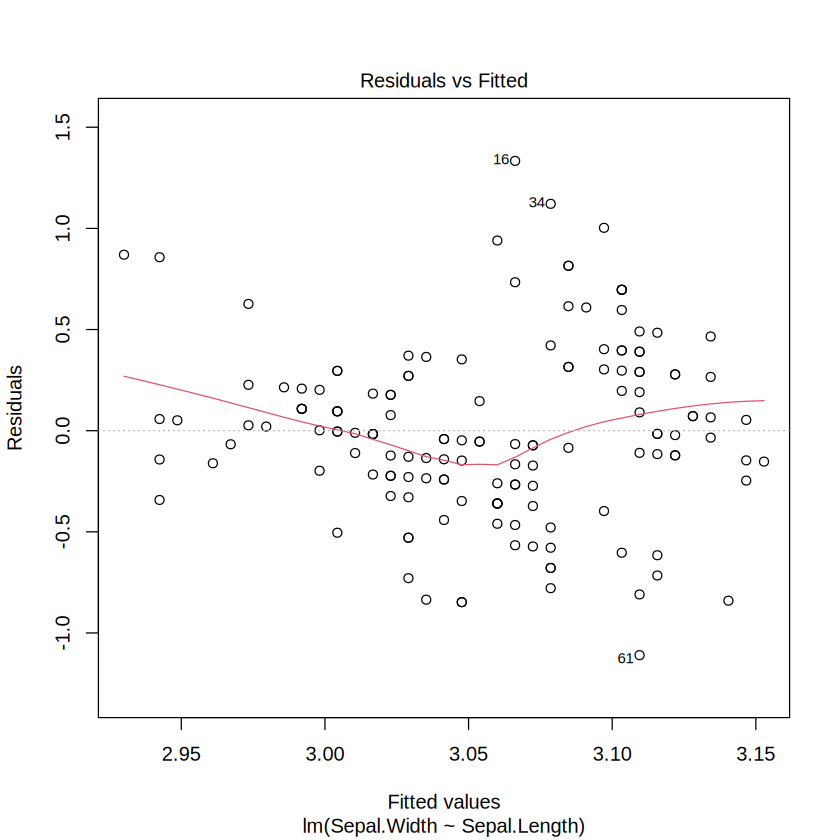

In [9]:
plot(modelo_lm, which = 1)

En este caso, la relación lineal es débil.
El modelo busca una recta, por cuanto, si los datos son una curva o no lineales, el modelo igual dibuja la recta pero esta no representa bien los datos.

**Homocedasticidad:** Significa que la variabilidad (dispersión) de los residuos o errores debe mantenerse constante a lo largo de todas las predicciones de nuestro modelo. Que el tamaño del error sea casi igual siempre. Importa porque el modelo solo calcula un margen de error para todos como si se equivocara siempre lo mismo.
El “margen de error” es σ (sigma). Es cuánto se dispersan esos errores en general, el tamaño típico del error.



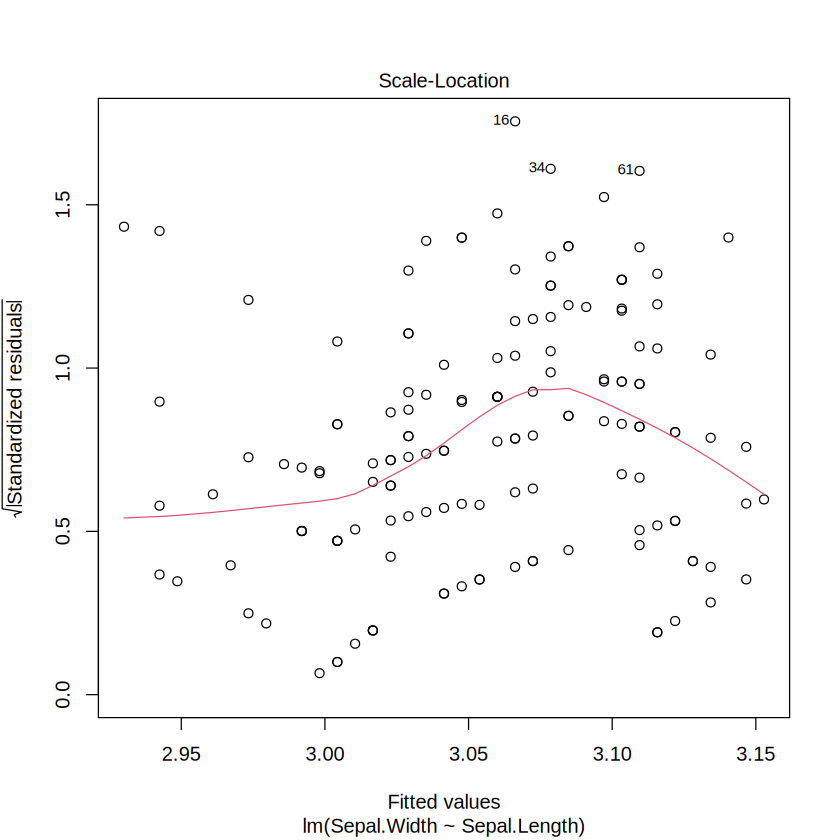

In [12]:
# Graficamos Scale-Location (gráfico número 3)
plot(modelo_lm, which = 3)

In [15]:
# Instalamos el paquete si es necesario y lo cargamos
if (!require(lmtest)) install.packages("lmtest")
library(lmtest)

# Ejecutamos el test de Breusch-Pagan
bptest(modelo_lm)

Loading required package: lmtest

Warning message in library(package, lib.loc = lib.loc, character.only = TRUE, logical.return = TRUE, :
“there is no package called ‘lmtest’”
Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependency ‘zoo’


Loading required package: zoo


Attaching package: ‘zoo’


The following objects are masked from ‘package:base’:

    as.Date, as.Date.numeric





	studentized Breusch-Pagan test

data:  modelo_lm
BP = 2.7365, df = 1, p-value = 0.09808


Si el $p valor < 0.05$ hay heterocedasticidad. Aquí hay homocedasticidad porque es mayor.

**Normalidad de los residuos:** los errores siguen una distribución en forma de campana alrededor del 0.
Caso que no se cumpla los p valores pueden fallar.

La hipótesis nula (H₀) es que los errores son normales.

p > 0.05: no rechazás H₀, así que el supuesto se cumple.
p < 0.05: rechazás H₀, así que los errores no son normales.

In [16]:
shapiro.test(residuals(modelo_lm))


	Shapiro-Wilk normality test

data:  residuals(modelo_lm)
W = 0.9901, p-value = 0.3738


**Independencia de los residuos:** el error de un caso no dice nada sobre el siguiente error.

In [18]:
dwtest(modelo_lm)


	Durbin-Watson test

data:  modelo_lm
DW = 1.2626, p-value = 2.061e-06
alternative hypothesis: true autocorrelation is greater than 0


Un valor de 'DW' cercano a 2 (y p-valor > 0.05) indica independencia de errores. El supuesto no se cumple porque es < 0.05.



**NO MULTICOLINEALIDAD:** las variables explicativas no deben estar muy relacionadas entre sí. Los β quedan inestables. Si sacás o agregás unos pocos datos, los coeficientes cambian muchísimo, y hasta pueden cambiar de signo. Los errores estándar se inflan. Variables que obviamente importan pueden salir “no significativas”. Solo tiene sentido con dos o más features.